In [2]:
from dotenv import load_dotenv
import os

import simfin as sf
from simfin.names import *

from utils import *
from pipeline import *

import pandas as pd

load_dotenv()


# Set your API-key for downloading data.
# Replace YOUR_API_KEY with your actual API-key.
sf.set_api_key(os.environ["SIMFIN_API_KEY"])

# Set the local directory where data-files are stored.
# The dir will be created if it does not already exist.
sf.set_data_dir('~/simfin_data/')

refresh_sp500_constituents_file()

Saved 503 constituents to sp500_constituents.csv


In [ ]:
companies = load_sp500_companies()
industries = sf.load_industries().reset_index()

sp500 = pd.merge(companies, industries, how="left", on="IndustryId")
chosen_sectors = []
universe = sp500[sp500["Sector"].isin(chosen_sectors)] if len(chosen_sectors)>0 else sp500
tickers = universe["Ticker"].tolist()

conn = get_connection()
create_tables(conn)
for _, row in universe.iterrows():
    upsert_securities(conn, row["Ticker"], row["Company Name"], row["Sector"], row.get("Industry"))

fetch_and_store_prices(conn, tickers)
failed = fetch_and_store_fundamentals(conn, tickers)
conn.close()
end_message = f'{len(failed)} tickers failed out of {len(tickers)}'
end_message += f'\nFailed tickers: {failed}' if len(failed)>0 else ''
print(end_message)

In [61]:
fundamentals_df = pd.read_sql_query("""
    SELECT *
    FROM Fundamentals
    ORDER BY period_end_date
""", conn)
fundamentals_df

,Ticker,period_end_date,report_date,is_estimated_report_date,fiscal_period,revenue,gross_profit,ebitda,ebit,net_income,total_equity,total_assets,total_liabilities,shares_outstanding
0,A,2020-10-31,2020-12-18,NaN,Q4,1.483000e+09,7.880000e+08,NaN,2.990000e+08,2.220000e+08,4.873000e+09,9.627000e+09,4.754000e+09,3.110000e+08
1,AMAT,2020-10-31,2020-12-11,NaN,Q4,4.688000e+09,2.130000e+09,NaN,1.283000e+09,1.131000e+09,1.057800e+10,2.235300e+10,1.177500e+10,9.200000e+08
2,BBY,2020-10-31,2020-11-30,NaN,Q3,1.185300e+10,2.795000e+09,NaN,6.720000e+08,3.910000e+08,4.086000e+09,2.120200e+10,1.711600e+10,2.637000e+08
3,CIEN,2020-10-31,2020-12-18,NaN,Q4,8.284800e+08,4.043490e+08,9.861300e+07,1.044640e+08,6.504100e+07,2.509597e+09,4.180917e+09,1.671320e+09,1.566230e+08
4,COO,2020-10-31,2020-12-11,NaN,Q4,6.816000e+08,4.240000e+08,6.590000e+07,1.001000e+08,8.120000e+07,3.824800e+09,6.737500e+09,2.912700e+09,1.984000e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6101,ZURN.SW,2026-06-30,2026-08-14,1.0,Q2,NaN,NaN,NaN,NaN,NaN,3.132300e+10,4.202140e+11,3.871260e+11,1.493693e+08
6102,PGHN.SW,2026-06-30,2026-08-14,1.0,Q2,NaN,NaN,NaN,NaN,NaN,1.464200e+09,6.192000e+09,4.727800e+09,2.575986e+07
6103,RO.SW,2026-06-30,2026-08-14,1.0,Q2,NaN,NaN,NaN,NaN,NaN,3.269300e+10,9.820100e+10,6.148500e+10,7.967659e+08
6104,NVDA,2026-07-31,2026-08-26,0.0,Q2,9.622100e+10,7.214200e+10,7.286100e+10,7.173400e+10,5.968800e+10,2.289840e+11,3.202720e+11,9.128800e+10,2.414700e+10


In [62]:
prices_df = pd.read_sql_query("""
    SELECT *
    FROM Prices
    ORDER BY Date
""", conn)
prices_df

,Ticker,Date,Open,High,Low,Close,Adj_Close,Volume
0,A,2020-10-12,106.450000,107.000000,105.320000,105.430000,101.320000,1003703
1,AAPL,2020-10-12,120.060000,125.180000,119.280000,124.400000,120.570000,240226769
2,ABBV,2020-10-12,88.170000,88.600000,87.320000,88.320000,69.980000,7314932
3,ABT,2020-10-12,110.250000,111.570000,109.760000,111.050000,99.250000,4201819
4,ACGL,2020-10-12,31.330000,31.850000,31.040000,31.710000,30.160000,1616508
...,...,...,...,...,...,...,...,...
606853,SQN.SW,2026-09-07,41.959999,41.980000,41.299999,41.459999,41.459999,125481
606854,TEMN.SW,2026-09-07,72.849998,72.849998,70.050003,70.349998,70.349998,114586
606855,UBSG.SW,2026-09-07,44.610001,44.660000,44.110001,44.360001,44.360001,3228833
606856,VACN.SW,2026-09-07,615.200012,632.000000,615.200012,629.599976,629.599976,36559


In [66]:
print(f'First date in Prices: {min(prices_df["Date"])}')
print(f'Last date in Prices: {max(prices_df["Date"])}')
print(f'First date in Fundamentals: {min(fundamentals_df["report_date"])}')
print(f'Last date in Fundamentals: {max(fundamentals_df["report_date"])}')

First date in Prices: 2020-10-12
Last date in Prices: 2026-09-07
First date in Fundamentals: 2020-11-19
Last date in Fundamentals: 2026-08-26


<Axes: xlabel='Date'>

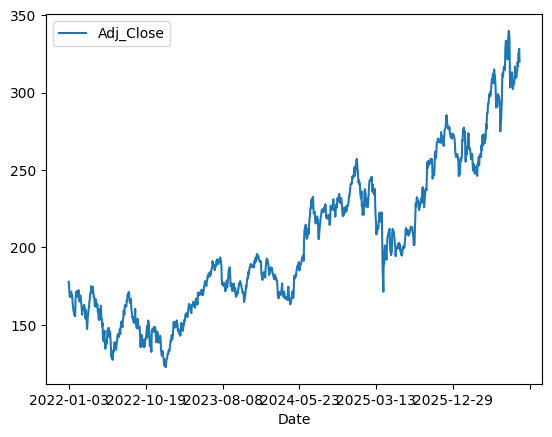

In [104]:
tickers = ["AAPL"]
prices_df = get_prices(conn, tickers=tickers, start_date="2022-01-01")
prices_df[prices_df["Ticker"]=="AAPL"].plot("Date", "Adj_Close")

In [105]:
dates = prices_df[["Ticker", "Date"]]
fundamentals_df = get_pit_fundamentals(conn, tickers, dates)
fundamentals_df.head()

,Ticker,Date,period_end_date,report_date,is_estimated_report_date,fiscal_period,revenue,gross_profit,ebitda,ebit,net_income,total_equity,total_assets,total_liabilities,shares_outstanding
0,AAPL,2022-01-03,2021-09-30,2021-10-29,NaN,Q4,8.336000e+10,3.517400e+10,NaN,2.378600e+10,2.055100e+10,6.309000e+10,3.510020e+11,2.879120e+11,1.651929e+10
1,AAPL,2022-01-04,2021-09-30,2021-10-29,NaN,Q4,8.336000e+10,3.517400e+10,NaN,2.378600e+10,2.055100e+10,6.309000e+10,3.510020e+11,2.879120e+11,1.651929e+10
2,AAPL,2022-01-05,2021-09-30,2021-10-29,NaN,Q4,8.336000e+10,3.517400e+10,NaN,2.378600e+10,2.055100e+10,6.309000e+10,3.510020e+11,2.879120e+11,1.651929e+10
3,AAPL,2022-01-06,2021-09-30,2021-10-29,NaN,Q4,8.336000e+10,3.517400e+10,NaN,2.378600e+10,2.055100e+10,6.309000e+10,3.510020e+11,2.879120e+11,1.651929e+10
4,AAPL,2022-01-07,2021-09-30,2021-10-29,NaN,Q4,8.336000e+10,3.517400e+10,NaN,2.378600e+10,2.055100e+10,6.309000e+10,3.510020e+11,2.879120e+11,1.651929e+10


In [124]:
rebalance_date = "2026-08-31"
ticker_prices = prices[prices["Ticker"].isin(tickers)]
index_rebalance_date = ticker_prices[ticker_prices["Date"]==rebalance_date].index
ticker_prices.loc[[416, 417]]

,Ticker,Date,Open,High,Low,Close,Adj_Close,Volume
416,AAPL,2025-08-29,232.51,233.38,231.37,232.14,231.28,39418437
417,AAPL,2025-09-02,229.25,230.85,226.97,229.72,228.87,44075638
